In [1]:
# import libraries

from pathlib import Path
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# set the data folder
data_dir = Path("data/tutorial05-data")

# load data center locations
data_centers = gpd.read_file(
    data_dir / "geocoded_data_centers/geocoded_data_centers.shp"
)

# load counties with population
counties = gpd.read_file(
    data_dir / "lower_48_counties_w_pop/lower_48_counties_w_pop.shp"
)

# load Core-Based Statistical Areas
cbsas = gpd.read_file(
    data_dir / "lower_48_cbsas/loewr_48_cbsas.shp"
)

# preview the county table
counties.head()

,GISJOIN,STATEFP,COUNTYFP,COUNTYNS,GEOID,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,...,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,Shape_Leng,Shape_Area,ORIG_FID,pop_AQNFE0,geometry
0,G0100010,01,001,00161526,01001,Autauga,Autauga County,06,H1,G4020,...,A,1.539631e+09,2.567754e+07,+32.5322367,-086.6464395,210512.579904,1.565309e+09,1318,58761,"POLYGON ((895625.242 -524091.396, 895192.828 -..."
1,G0100030,01,003,00161527,01003,Baldwin,Baldwin County,06,H1,G4020,...,A,4.117725e+09,1.132887e+09,+30.6592183,-087.7460666,673053.782447,4.254330e+09,1238,233420,"MULTIPOLYGON (((810181.191 -770353.651, 810167..."
2,G0100050,01,005,00161528,01005,Barbour,Barbour County,06,H1,G4020,...,A,2.292160e+09,5.052321e+07,+31.8702531,-085.4051035,272036.648100,2.342684e+09,1821,24877,"POLYGON ((1026117.28 -548829.885, 1026126.521 ..."
3,G0100070,01,007,00161529,01007,Bibb,Bibb County,06,H1,G4020,...,A,1.612189e+09,9.572302e+06,+33.0158929,-087.1271475,190851.068806,1.621761e+09,3006,22251,"POLYGON ((845023.464 -457350.174, 845421.934 -..."
4,G0100090,01,009,00161530,01009,Blount,Blount County,06,H1,G4020,...,A,1.670259e+09,1.486028e+07,+33.9773575,-086.5664400,242282.037461,1.685119e+09,852,59077,"POLYGON ((886438.269 -335474.799, 886435.536 -..."


In [3]:
# inspect the coordinate reference systems

print("Data centers:", data_centers.crs)
print("Counties:", counties.crs)
print("CBSAs:", cbsas.crs)

Data centers: EPSG:4326
Counties: PROJCS["USA_Contiguous_Albers_Equal_Area_Conic",GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6269"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4269"]],PROJECTION["Albers_Conic_Equal_Area"],PARAMETER["latitude_of_center",37.5],PARAMETER["longitude_of_center",-96],PARAMETER["standard_parallel_1",29.5],PARAMETER["standard_parallel_2",45.5],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["ESRI","102003"]]
CBSAs: PROJCS["USA_Contiguous_Albers_Equal_Area_Conic",GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6269"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHO

In [4]:
# use a common projection for the contiguous United States
target_crs = "EPSG:5070"

data_centers = data_centers.to_crs(target_crs)
counties = counties.to_crs(target_crs)
cbsas = cbsas.to_crs(target_crs)

# confirm that all three layers now use the same CRS
print("Data centers:", data_centers.crs)
print("Counties:", counties.crs)
print("CBSAs:", cbsas.crs)

Data centers: EPSG:5070
Counties: EPSG:5070
CBSAs: EPSG:5070


Data centers negli USA: 1988


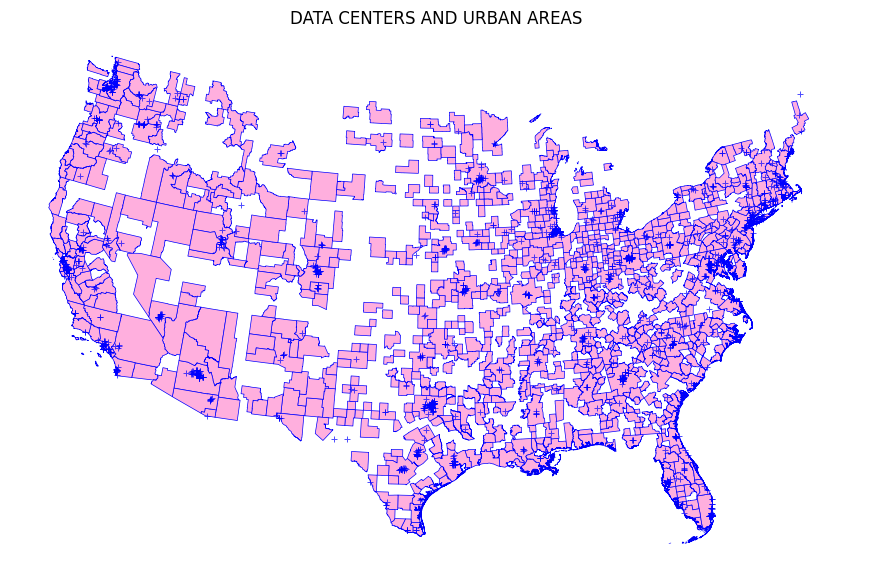

In [20]:
# create the figure
fig, ax = plt.subplots(figsize=(11, 8.5))

# draw counties as the background
counties.plot(
    ax=ax,
    facecolor="#fFFFFF",
    edgecolor="white",
    linewidth=0.2
)

# add statistical areas
cbsas.plot(
    ax=ax,
    facecolor="#FFAFDE",
    edgecolor="#0000FF",
    linewidth=0.5,
)

# keep only points inside the contiguous USA
data_centers_usa = gpd.sjoin(
    data_centers,
    counties[["geometry"]],
    how="inner",
    predicate="intersects"
)

# remove duplicate points and the join reference
data_centers_usa = data_centers_usa.loc[
    ~data_centers_usa.index.duplicated()
].drop(columns="index_right")

print("Data centers negli USA:", len(data_centers_usa))

# add data centers on top
data_centers_usa.plot(
    ax=ax,
    marker="+",
    color="#0000FF",
    markersize=20,
    linewidth=0.7,
    alpha=0.7
)

ax.set_title("DATA CENTERS AND URBAN AREAS")
ax.set_axis_off()

plt.show()

In [12]:
# match each data center to its county
points_in_counties = gpd.sjoin(
    data_centers_usa,
    counties[["geometry"]],
    how="inner",
    predicate="within"
)

# count points by county index
counts = points_in_counties.groupby("index_right").size()

# add the counts to a copy of the counties
counties_counts = counties.copy()

counties_counts["NUMPOINTS"] = (
    counties_counts.index.to_series()
    .map(counts)
    .fillna(0)
    .astype(int)
)

# inspect counties with the most data centers
counties_counts.sort_values(
    "NUMPOINTS", ascending=False
).head()

,GISJOIN,STATEFP,COUNTYFP,COUNTYNS,GEOID,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,...,ALAND,AWATER,INTPTLAT,INTPTLON,Shape_Leng,Shape_Area,ORIG_FID,pop_AQNFE0,geometry,NUMPOINTS
2839,G5101070,51,107,01480141,51107,Loudoun,Loudoun County,06,H1,G4020,...,1.335753e+09,1.449636e+07,+39.0812000,-077.6388976,187080.984337,1.350250e+09,2952,420773,"POLYGON ((1576009.385 1953829.027, 1576007.976...",114
199,G0600850,06,085,00277307,06085,Santa Clara,Santa Clara County,06,H1,G4020,...,3.343893e+09,3.359585e+07,+37.2216142,-121.6895401,344529.478700,3.367511e+09,1938,1916831,"POLYGON ((-2259385.021 1915358.751, -2259392.8...",93
2546,G4801130,48,113,01383842,48113,Dallas,Dallas County,06,H1,G4020,...,2.261430e+09,9.166978e+07,+32.7669866,-096.7784238,194013.898798,2.353100e+09,2489,2604053,"POLYGON ((-78404.233 1102239.929, -78343.126 1...",84
577,G1700310,17,031,01784766,17031,Cook,Cook County,06,H1,G4020,...,2.447343e+09,1.786339e+09,+41.8942937,-087.6454546,306952.257543,2.480097e+09,643,5225367,"POLYGON ((699258.385 2109466.799, 699259.63 21...",81
175,G0600370,06,037,00277283,06037,Los Angeles,Los Angeles County,06,H1,G4020,...,1.051599e+10,1.785003e+09,+34.1963983,-118.2618616,835636.035660,1.058183e+10,396,9936690,"MULTIPOLYGON (((-2068638.892 1326177.751, -206...",67


In [24]:
from matplotlib.colors import ListedColormap

pink_cmap = ListedColormap([
    "#ffffff",
    "#ffd1ff",
    "#ffa5ff",
    "#ff84ff",
    "#ff00ff"
])

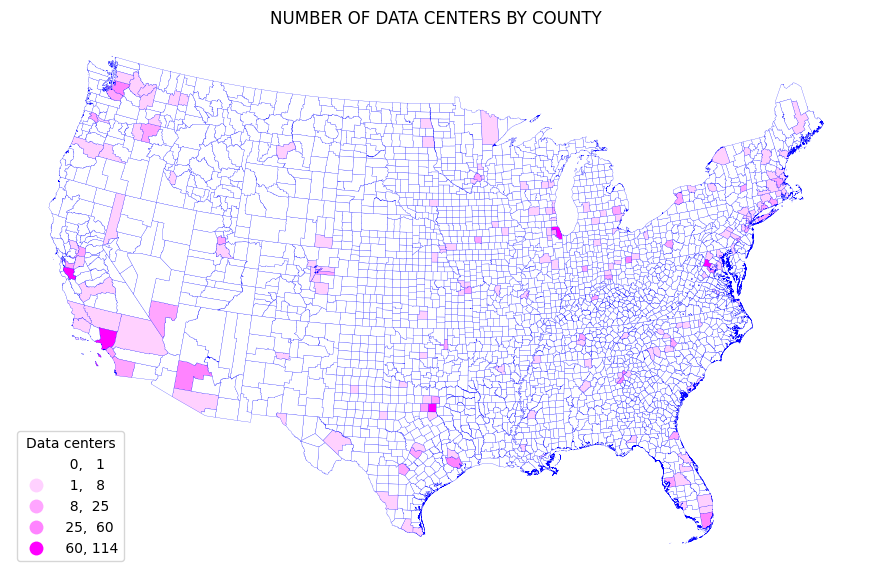

In [25]:
# map data center counts by county
fig, ax = plt.subplots(figsize=(11, 8.5))

counties_counts.plot(
    ax=ax,
    column="NUMPOINTS",
    scheme="natural_breaks",
    k=5,
    cmap=pink_cmap,
    edgecolor="#0000FF",
    linewidth=0.15,
    legend=True,
    legend_kwds={
        "title": "Data centers",
        "loc": "lower left",
        "fmt": "{:.0f}"
    }
)

ax.set_title("NUMBER OF DATA CENTERS BY COUNTY")
ax.set_axis_off()

plt.show()

In [26]:
# inspect the available fields
print(counties_counts.columns.tolist())

# preview population and land area
counties_counts[["pop_AQNFE0", "ALAND"]].head()

['GISJOIN', 'STATEFP', 'COUNTYFP', 'COUNTYNS', 'GEOID', 'NAME', 'NAMELSAD', 'LSAD', 'CLASSFP', 'MTFCC', 'CSAFP', 'CBSAFP', 'METDIVFP', 'FUNCSTAT', 'ALAND', 'AWATER', 'INTPTLAT', 'INTPTLON', 'Shape_Leng', 'Shape_Area', 'ORIG_FID', 'pop_AQNFE0', 'geometry', 'NUMPOINTS']


,pop_AQNFE0,ALAND
0,58761,1.539631e+09
1,233420,4.117725e+09
2,24877,2.292160e+09
3,22251,1.612189e+09
4,59077,1.670259e+09


In [27]:
# convert population values to numbers
counties_counts["population"] = pd.to_numeric(
    counties_counts["pop_AQNFE0"],
    errors="coerce"
)

# calculate total county area in square kilometres
counties_counts["area_km2"] = (
    counties_counts.geometry.area / 1_000_000
)

# calculate population density
counties_counts["pop_density"] = (
    counties_counts["population"]
    / counties_counts["area_km2"]
)

# inspect the results
counties_counts[
    ["population", "area_km2", "pop_density"]
].head()

,population,area_km2,pop_density
0,58761,1565.309074,37.539551
1,233420,4254.329836,54.866456
2,24877,2342.683550,10.619019
3,22251,1621.761112,13.720270
4,59077,1685.119450,35.058049


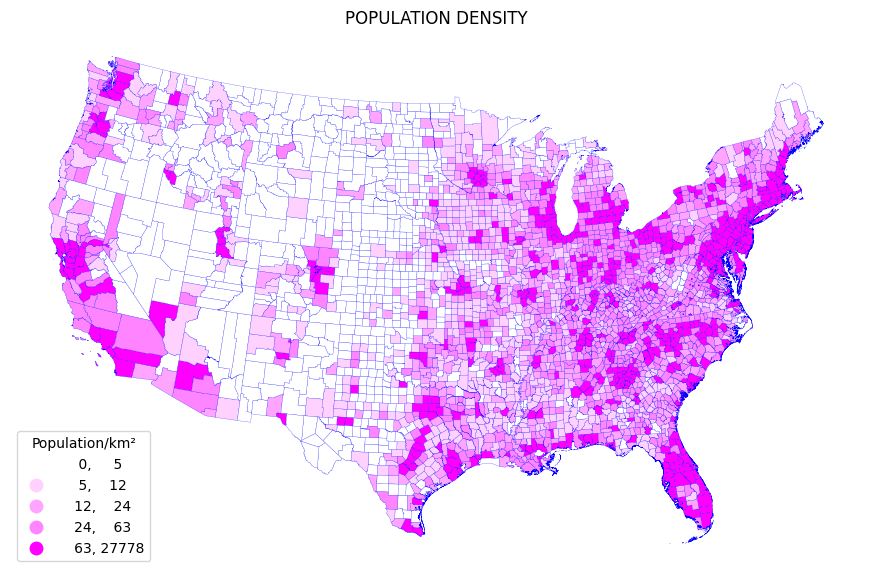

In [30]:
# map population density
fig, ax = plt.subplots(figsize=(11, 8.5))

counties_counts.plot(
    ax=ax,
    column="pop_density",
    scheme="quantiles",
    k=5,
    cmap=pink_cmap,
    edgecolor="#0000ff",
    linewidth=0.15,
    legend=True,
    legend_kwds={
        "title": "Population/km²",
        "loc": "lower left",
        "fmt": "{:.0f}"
    },
    missing_kwds={
        "color": "lightgrey",
        "label": "Dati mancanti"
    }
)

ax.set_title("POPULATION DENSITY")
ax.set_axis_off()

plt.show()

In [31]:
# keep a geometry-only copy of the data center locations
voronoi_points = data_centers_usa[["geometry"]].copy()

# remove empty or missing geometries
voronoi_points = voronoi_points.loc[
    voronoi_points.geometry.notna()
    & ~voronoi_points.geometry.is_empty
]

# keep one point per unique location
voronoi_points = (
    voronoi_points
    .drop_duplicates(subset="geometry")
    .reset_index(drop=True)
)

# assign an ID to each location
voronoi_points["VID"] = voronoi_points.index

print("Data centers:", len(data_centers_usa))
print("Posizioni uniche:", len(voronoi_points))

Data centers: 1988
Posizioni uniche: 1594


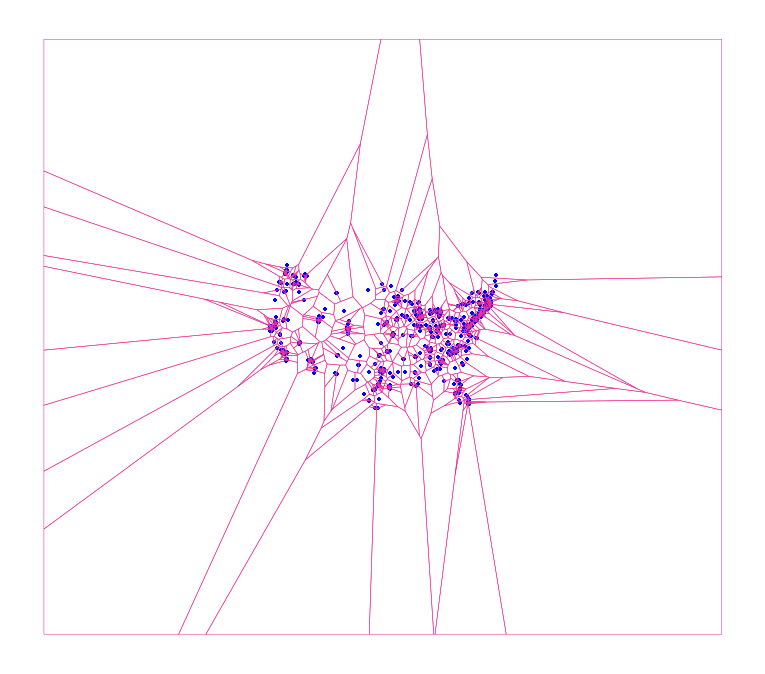

In [ ]:
from shapely.geometry import MultiPoint
from shapely.ops import voronoi_diagram

# combine the unique locations into one geometry
points_geometry = MultiPoint(
    voronoi_points.geometry.tolist()
)

# define an extent that covers all our counties
study_extent = counties_counts.total_bounds

from shapely.geometry import box

envelope = box(*study_extent)

# generate the Voronoi polygons
diagram = voronoi_diagram(
    points_geometry,
    envelope=envelope
)

# turn the polygons into a GeoDataFrame
voronoi = gpd.GeoDataFrame(
    geometry=list(diagram.geoms),
    crs=voronoi_points.crs
)

# associate each polygon with its data center location ID
voronoi = gpd.sjoin(
    voronoi,
    voronoi_points[["VID", "geometry"]],
    how="left",
    predicate="contains"
).drop(columns="index_right")

# preview the zones
fig, ax = plt.subplots(figsize=(11, 8.5))

voronoi.boundary.plot(
    ax=ax,
    color="#ed3395",
    linewidth=0.15
)

voronoi_points.plot(
    ax=ax,
    marker="+",
    color="blue",
    markersize=3
)

ax.set_axis_off()
plt.show()

In [ ]:
# merge all counties into a single study-area boundary
usa_boundary = counties_counts[["geometry"]].dissolve()

# clip the Voronoi polygons to the USA boundary
voronoi_usa = gpd.clip(voronoi, usa_boundary)

# plot the clipped zones
fig, ax = plt.subplots(figsize=(11, 8.5))

voronoi_usa.plot(
    ax=ax,
    facecolor="#f06292",
    edgecolor="#333333",
    linewidth=0.4
)

ax.set_axis_off()
plt.show()